<a href="https://colab.research.google.com/github/josephjuma24/500-AI-Agents-Projects/blob/main/mge_bigan_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Multi-Generator Encoder-Based Bidirectional Generative Adversarial Network (MGE-BiGAN) for Network Intrusion Detection

## 1. Problem Context & Architectural Formulation
Production network telemetry is heavily imbalanced (> 99% benign). Conventional classifiers suffer from the *Accuracy Paradox* under extreme class imbalances. Standard generative resampling techniques distort high-dimensional decision boundaries or suffer from mode collapse on rare threat families.

### Architectural Topology
```
                 Tag Embedding Matrix M_tag
                          │ Class Tag Vector e_c
            ┌─────────────┴──────────────┐
            ▼                            ▼
     Real Flow x ~ P_data(x)     Gaussian Noise z ~ N(0, I_d)
            ▼                            ▼
  Tag-Conditioned Encoder E(x,e_c)   Multi-Generator Engine G_k(z,e_c), k∈{1..K}
            │ latent projection ẑ        │ synthetic flow x̂
   Real Joint Pair [x ‖ ẑ]       Synthetic Joint Pair [x̂ ‖ z]
            └─────────────┬──────────────┘
                          ▼
              Joint Space Discriminator D(x, z)
                ┌─────────┴─────────┐
                ▼                   ▼
  Wasserstein Critic Head     Auxiliary Focal Classifier
       D_critic(x, z)                C_aux(x)
```

### Assumptions & Deviations Log
| # | Gap in PRD | Engineering Resolution Applied |
|---|---|---|
| **R1** | Mode B uses $E(x')$, but encoder needs $e_c$ which is unknown at inference. | **Resolution:** Default `aux_then_encode`: (1) Run $E$ with a learned **'unknown' tag** ($K$-th row in embedding, trained with 10% dropout); (2) get $C_{aux}$ prediction $\hat{c}$; (3) re-encode with $e_{\hat{c}}$ and score. |
| **R2** | $S = \sigma(D) > 0.5$ assumes "higher = anomalous", but WGAN critic outputs are unbounded. | **Resolution:** Anomaly score calibrated as $\sigma(s \cdot (D - b)/T)$, with orientation $s$, offset $b$, and temperature $T$ fitted on validation split. |
| **R3** | $\log(1+x)$ is undefined for $x \le -1$ (common in some CIC-IDS features). | **Resolution:** Apply sign-preserving $\text{sign}(x) \cdot \log(1 + |x|)$ mapping. |
| **R4** | IQR = 0 for near-constant features. | **Resolution:** Fall back to `iqr = 1.0` if computed $\text{IQR} < 10^{-9}$. Drop features that are constant on the training set. |
| **R5** | $\alpha_c$ in focal loss is unspecified. | **Resolution:** Effective-number weights $\alpha_c \propto (1 - \beta)/(1 - \beta^{n_c})$ with $\beta = 0.999$ computed strictly from training partition counts. |
| **R6** | $\tau$ in $\mathcal{L}_{div}$ is unspecified. | **Resolution:** Default $\tau = 1.0$, tuned in Optuna search space $[0.5, 2.0]$. |
| **R7** | $K$ sub-generators versus 1 including benign. | **Resolution:** Build $K$ Generators (one per class, including Benign). Benign generator is not oversampled in Mode A. |
| **R8** | BatchNorm in sub-generators fails on sub-batch size 1. | **Resolution:** Implement a `ClassBalancedBatchSampler` ensuring $\ge 2$ samples per class per mini-batch. |
| **R9** | $C_{aux}$ input discrepancy (diagram vs. code). | **Resolution:** Feed joint $[x \parallel z]$ penultimate features into $C_{aux}$ classifier head. |
| **R10**| Long training epochs over millions of rows. | **Resolution:** Define epoch as a fixed number of balanced optimization steps (`steps_per_epoch = 500`). |

In [1]:
# Cell 1: Environment and dependency installation
!pip install -q optuna typing_extensions onnx onnxruntime onnxscript torchinfo ndg-httpsclient pyopenssl urllib3 > /dev/null

import os
import sys
import random
import json
import time
import logging
import zipfile
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# Configure logging
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s [%(levelname)s] %(message)s',
    handlers=[logging.StreamHandler(sys.stdout)]
)

# System Info
print(f"Python Version: {sys.version}")
print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Name: {torch.cuda.get_device_name(0)}")
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")

Python Version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
PyTorch Version: 2.14.1+cpu
CUDA Available: False


In [ ]:
# Cell 2: Config Dataclass & Global Seed Initialization
from dataclasses import dataclass, field
from typing import List, Dict, Any, Optional

@dataclass
class Config:
    seed: int = 42
    dataset: str = "unsw_nb15" # Options: "cic_ids2018", "unsw_nb15"
    quick_mode: bool = True  # Smoke test flag for fast verification

    # Dimensions
    noise_dim: int = 32
    tag_dim: int = 16
    feature_dim: int = 42 # Default for unsw_nb15; dynamically set later
    num_classes: int = 10 # Default for unsw_nb15; dynamically set later

    # Hyperparameters
    gp_lambda: float = 10.0
    focal_lambda: float = 1.0
    div_lambda: float = 0.1
    div_tau: float = 1.0
    focal_gamma: float = 2.0

    # Training
    batch_size: int = 128
    epochs_stage1: int = 10 # Will be overridden in non-quick mode
    epochs_stage2: int = 20 # Will be overridden in non-quick mode
    steps_per_epoch: int = 100
    lr_g: float = 1e-4
    lr_e: float = 1e-4
    lr_d: float = 2e-4
    n_critic: int = 5

    # Paths
    artifact_dir: str = "artifacts/mge_bigan/"

CONFIG = Config()

# Set seeds
def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(CONFIG.seed)

In [ ]:
# Cell 3: Robust Mock Dataset Generator (Ensures complete execution)
def generate_synthetic_telemetry(dataset_name: str, num_samples: int = 15000) -> pd.DataFrame:
    """
    Generates an analytical, imbalanced dataset matching the structure of
    the requested network threat profile.
    """
    np.random.seed(CONFIG.seed)
    if dataset_name == "unsw_nb15":
        classes = ['Normal', 'Generic', 'Exploits', 'Fuzzers', 'DoS', 'Reconnaissance', 'Analysis', 'Backdoor', 'Shellcode', 'Worms']
        probs = [0.85, 0.08, 0.03, 0.02, 0.01, 0.005, 0.003, 0.001, 0.0008, 0.0002] # Extreme long tail
        selected_classes = np.random.choice(classes, size=num_samples, p=probs)

        # Features mapping
        data = {
            'dur': np.random.exponential(scale=1.5, size=num_samples),
            'spkts': np.random.randint(1, 1000, size=num_samples).astype(float),
            'dpkts': np.random.randint(1, 1000, size=num_samples).astype(float),
            'sbytes': np.random.exponential(scale=10000, size=num_samples),
            'dbytes': np.random.exponential(scale=15000, size=num_samples),
            'rate': np.random.exponential(scale=5000, size=num_samples),
            'sttl': np.random.randint(0, 256, size=num_samples).astype(float),
            'dttl': np.random.randint(0, 256, size=num_samples).astype(float),
            'sload': np.random.exponential(scale=1e6, size=num_samples),
            'dload': np.random.exponential(scale=1e6, size=num_samples),
            'sloss': np.random.randint(0, 100, size=num_samples).astype(float),
            'dloss': np.random.randint(0, 100, size=num_samples).astype(float),
            'sinpkt': np.random.exponential(scale=50, size=num_samples),
            'dinpkt': np.random.exponential(scale=50, size=num_samples),
            'sjit': np.random.exponential(scale=10, size=num_samples),
            'djit': np.random.exponential(scale=10, size=num_samples),
            'swin': np.random.choice([0.0, 255.0], size=num_samples),
            'stcpb': np.random.randint(0, 1e9, size=num_samples).astype(float),
            'dtcpb': np.random.randint(0, 1e9, size=num_samples).astype(float),
            'dwin': np.random.choice([0.0, 255.0], size=num_samples),
            'tcprtt': np.random.exponential(scale=0.1, size=num_samples),
            'synack': np.random.exponential(scale=0.05, size=num_samples),
            'ackdat': np.random.exponential(scale=0.05, size=num_samples),
            'smean': np.random.randint(20, 1500, size=num_samples).astype(float),
            'dmean': np.random.randint(20, 1500, size=num_samples).astype(float),
            'trans_depth': np.random.randint(0, 3, size=num_samples).astype(float),
            'response_body_len': np.random.exponential(scale=2000, size=num_samples),
            'ct_srv_src': np.random.randint(1, 20, size=num_samples).astype(float),
            'ct_state_ttl': np.random.randint(0, 6, size=num_samples).astype(float),
            'ct_dst_ltm': np.random.randint(1, 20, size=num_samples).astype(float),
            'ct_src_dport_ltm': np.random.randint(1, 20, size=num_samples).astype(float),
            'ct_dst_sport_ltm': np.random.randint(1, 20, size=num_samples).astype(float),
            'ct_dst_src_ltm': np.random.randint(1, 20, size=num_samples).astype(float),
            'is_ftp_login': np.random.choice([0.0, 1.0], size=num_samples),
            'ct_ftp_cmd': np.random.randint(0, 5, size=num_samples).astype(float),
            'ct_flw_http_mthd': np.random.randint(0, 5, size=num_samples).astype(float),
            'ct_src_ltm': np.random.randint(1, 20, size=num_samples).astype(float),
            'ct_srv_dst': np.random.randint(1, 20, size=num_samples).astype(float),
            'is_sm_ips_ports': np.random.choice([0.0, 1.0], size=num_samples),
            'proto': np.random.choice(['tcp', 'udp', 'unas'], size=num_samples),
            'service': np.random.choice(['-', 'dns', 'http', 'smtp'], size=num_samples),
            'state': np.random.choice(['FIN', 'INT', 'CON', 'REQ'], size=num_samples),
            'attack_cat': selected_classes
        }

    else: # cic_ids2018 default simulation
        classes = ['Benign', 'DDOS-HOIC', 'DDoS-LOIC-HTTP', 'DoS-GoldenEye', 'DoS-Slowloris',
                   'DoS-SlowHTTPTest', 'DoS-Hulk', 'FTP-BruteForce', 'SSH-Bruteforce',
                   'Infiltration', 'Bot', 'Web Attack-Brute Force', 'Web Attack-XSS', 'SQL Injection']
        probs = [0.90, 0.05, 0.02, 0.01, 0.005, 0.004, 0.005, 0.003, 0.002, 0.001, 0.0005, 0.0002, 0.0001, 0.00005]
        probs = np.array(probs) / np.sum(probs)
        selected_classes = np.random.choice(classes, size=num_samples, p=probs)

        # Generate 78 float attributes dynamically to sum up to continuous dimension D=78 + 2 categorical = D=80
        data = {}
        for i in range(78):
            data[f'Flow_Feature_{i}'] = np.random.exponential(scale=10.0, size=num_samples) - 1.0 # contains some negative/zero features
        data['Protocol'] = np.random.choice(['TCP', 'UDP', 'ICMP'], size=num_samples)
        data['DstPort'] = np.random.choice(['80', '443', '22', '53'], size=num_samples)
        data['Label'] = selected_classes

    df = pd.DataFrame(data)
    # Ensure some Inf and NaNs are present for cleanup validation
    for col in df.select_dtypes(include=[np.number]).columns[:3]:
        nan_idx = np.random.choice(num_samples, size=int(num_samples * 0.001), replace=False)
        inf_idx = np.random.choice(num_samples, size=int(num_samples * 0.001), replace=False)
        df.loc[nan_idx, col] = np.nan
        df.loc[inf_idx, col] = np.inf
    return df

In [ ]:
# Cell 4: Load & Segment Data into Parquet Cache
os.makedirs(CONFIG.artifact_dir, exist_ok=True)
raw_df = generate_synthetic_telemetry(CONFIG.dataset, num_samples=15000)

# Quick report of missing / skew telemetry
print(f"Raw dataset shape: {raw_df.shape}")
print(f"Missing values count: {raw_df.isna().sum().sum()}")
print(f"Infinite values count: {np.isinf(raw_df.select_dtypes(include=[np.number])).sum().sum()}")

# Save to Parquet cache
raw_df.to_parquet(os.path.join(CONFIG.artifact_dir, f"raw_{CONFIG.dataset}.parquet"))

Raw dataset shape: (15000, 43)
Missing values count: 45
Infinite values count: 45


In [ ]:
# Cell 5: Fold-Contained Preprocessor Implementation with Leakage Audit
from sklearn.base import BaseEstimator, TransformerMixin

class FoldContainedPreprocessor(BaseEstimator, TransformerMixin):
    def __init__(self, dataset_name: str, skew_threshold: float = 1.0):
        self.dataset_name = dataset_name
        self.skew_threshold = skew_threshold
        self.is_fitted = False

        self.medians = {}
        self.iqrs = {}
        self.skewed_cols = []
        self.cat_mappings = {}
        self.numeric_cols = []
        self.categorical_cols = []
        self.label_col = ""
        self.classes = []
        self.class_to_idx = {}
        self.idx_to_class = {}

    def fit(self, X: pd.DataFrame):
        df = X.copy()
        # Establish Targets
        if self.dataset_name == "unsw_nb15":
            self.label_col = "attack_cat"
            self.categorical_cols = [col for col in ['proto', 'service', 'state'] if col in df.columns]
        else:
            self.label_col = "Label"
            self.categorical_cols = [col for col in ['Protocol', 'DstPort'] if col in df.columns]

        # Standardize labels mapping
        labels = df[self.label_col].astype(str).str.strip().str.lower().unique()
        labels = sorted(list(labels))
        # Make sure benign is at index 0
        benign_variants = ['normal', 'benign']
        benign_val = next((l for l in labels if l in benign_variants), labels[0])
        labels.remove(benign_val)
        self.classes = [benign_val] + labels
        self.class_to_idx = {name: idx for idx, name in enumerate(self.classes)}
        self.idx_to_class = {idx: name for idx, name in enumerate(self.classes)}

        self.numeric_cols = [col for col in df.columns if col not in self.categorical_cols + [self.label_col]]

        # Fit statistics
        for col in self.numeric_cols:
            series = df[col].replace([np.inf, -np.inf], np.nan)
            median = series.median()
            if pd.isna(median):
                median = 0.0
            self.medians[col] = median

            # Replace for IQR calculation
            clean_series = series.fillna(median)
            q75, q25 = np.percentile(clean_series, [75 ,25])
            iqr = q75 - q25
            if iqr < 1e-9:
                iqr = 1.0 # R4 Resolution
            self.iqrs[col] = iqr

            # Skew calculation
            if clean_series.skew() > self.skew_threshold:
                self.skewed_cols.append(col)

        # Categorical maps
        for col in self.categorical_cols:
            cats = df[col].astype(str).unique()
            self.cat_mappings[col] = list(cats)

        self.is_fitted = True
        return self

    def transform(self, X: pd.DataFrame) -> tuple:
        if not self.is_fitted:
            raise ValueError("Preprocessor must be fitted first.")
        df = X.copy()

        # Fill infinites and NaNs strictly from precalculated medians
        for col in self.numeric_cols:
            df[col] = df[col].replace([np.inf, -np.inf], np.nan)
            df[col] = df[col].fillna(self.medians[col])

            # R3: Sign-preserving log compression
            if col in self.skewed_cols:
                df[col] = np.sign(df[col]) * np.log1p(np.abs(df[col]))

            # Scaling
            df[col] = (df[col] - self.medians[col]) / self.iqrs[col]

        # Continuous category transformations
        cat_encoded_dfs = []
        for col in self.categorical_cols:
            mappings = self.cat_mappings[col]
            for cat in mappings:
                col_name = f"{col}_{cat}"
                df[col_name] = (df[col].astype(str) == cat).astype(float)
            cat_encoded_dfs.append(df[[f"{col}_{c}" for c in mappings]])

        final_num_df = df[self.numeric_cols]
        if cat_encoded_dfs:
            final_features = pd.concat([final_num_df] + cat_encoded_dfs, axis=1)
        else:
            final_features = final_num_df

        # Encode target classes
        mapped_labels = df[self.label_col].astype(str).str.strip().str.lower().map(self.class_to_idx).fillna(0).astype(int)

        return torch.tensor(final_features.values, dtype=torch.float32), torch.tensor(mapped_labels.values, dtype=torch.long)

In [ ]:
# Cell 6: Verify FoldContainedPreprocessor and Run Zero Leakage Audit
preprocessor = FoldContainedPreprocessor(CONFIG.dataset)
test_split_idx = int(len(raw_df) * 0.8)
train_df = raw_df.iloc[:test_split_idx]
test_df = raw_df.iloc[test_split_idx:]

preprocessor.fit(train_df)

# Snapshot parameters before transforming test telemetry
median_snapshots = dict(preprocessor.medians)
transform_features_tr, transform_labels_tr = preprocessor.transform(train_df)
transform_features_te, transform_labels_te = preprocessor.transform(test_df)

# Audit Assertions
assert len(preprocessor.medians) == len(median_snapshots), "Imputation arrays dynamically changed during test prediction!"
for key in median_snapshots:
    assert preprocessor.medians[key] == median_snapshots[key], f"Statistical leakage detected in parameter {key}!"

# Update CONFIG dimensions based on actual processed shapes
CONFIG.feature_dim = transform_features_tr.shape[1]
CONFIG.num_classes = len(preprocessor.classes)
print(f"Leakage Audit Passed successfully!")
print(f"Dimensions configured -> Features: {CONFIG.feature_dim}, Classes: {CONFIG.num_classes}")

Leakage Audit Passed successfully!
Dimensions configured -> Features: 50, Classes: 9


In [ ]:
# Cell 7: MGE-BiGAN Core Network Architectures & Modules
import torch
import torch.nn as nn
import torch.optim as optim
from torch.nn.utils import spectral_norm

class ClassTagEmbedding(nn.Module):
    """
    Trainable dense class conditioning matrix.
    Includes an extra row (index K) to support R1 'unknown' tag inference strategies.
    """
    def __init__(self, num_classes: int, embedding_dim: int = 16):
        super().__init__()
        self.embedding = nn.Embedding(num_classes + 1, embedding_dim) # +1 for R1 'unknown' strategy

    def forward(self, class_labels: torch.Tensor) -> torch.Tensor:
        return self.embedding(class_labels)


class SingleClassGenerator(nn.Module):
    """
    Decoupled sub-generator dedicated to generating features for a single specific class.
    """
    def __init__(self, noise_dim: int = 32, tag_dim: int = 16, feature_dim: int = 50):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(noise_dim + tag_dim, 128),
            nn.BatchNorm1d(128),
            nn.LeakyReLU(0.2, inplace=False),

            nn.Linear(128, 256),
            nn.BatchNorm1d(256),
            nn.LeakyReLU(0.2, inplace=False),

            nn.Linear(256, 512),
            nn.BatchNorm1d(512),
            nn.LeakyReLU(0.2, inplace=False),

            nn.Linear(512, feature_dim)
        )

    def forward(self, z: torch.Tensor, e_c: torch.Tensor) -> torch.Tensor:
        x = torch.cat([z, e_c], dim=-1)
        return self.net(x)


class MultiGeneratorEngine(nn.Module):
    """
    Manages the K structurally independent sub-generators with gradient isolation (FR-1).
    """
    def __init__(self, num_classes: int, noise_dim: int = 32, tag_dim: int = 16, feature_dim: int = 50):
        super().__init__()
        self.generators = nn.ModuleList([
            SingleClassGenerator(noise_dim, tag_dim, feature_dim) for _ in range(num_classes)
        ])
        self.num_classes = num_classes

    def forward(self, z: torch.Tensor, e_c: torch.Tensor, class_labels: torch.Tensor) -> torch.Tensor:
        batch_size = z.size(0)
        outputs = torch.empty((batch_size, self.generators[0].net[-1].out_features), device=z.device, dtype=z.dtype)

        for c in range(self.num_classes):
            mask = (class_labels == c)
            if mask.any():
                # Forward pass is cleanly routed to ensure gradient isolation
                outputs[mask] = self.generators[c](z[mask], e_c[mask])
        return outputs


class TagConditionedEncoder(nn.Module):
    """
    Bidirectional projection encoder mapping flow telemetry features to latents (FR-2).
    """
    def __init__(self, feature_dim: int, tag_dim: int = 16, latent_dim: int = 32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(feature_dim + tag_dim, 512),
            nn.LeakyReLU(0.2, inplace=False),

            nn.Linear(512, 256),
            nn.LeakyReLU(0.2, inplace=False),

            nn.Linear(256, 128),
            nn.LeakyReLU(0.2, inplace=False),

            nn.Linear(128, latent_dim)
        )

    def forward(self, x: torch.Tensor, e_c: torch.Tensor) -> torch.Tensor:
        inputs = torch.cat([x, e_c], dim=-1)
        return self.net(inputs)


class JointWassersteinCritic(nn.Module):
    """
    Wasserstein Joint Space Critic with Spectral Normalization on all linear layers (FR-3, FR-4).
    No Batch Normalization is utilized in this critic.
    """
    def __init__(self, feature_dim: int, latent_dim: int = 32, num_classes: int = 10):
        super().__init__()
        self.shared = nn.Sequential(
            spectral_norm(nn.Linear(feature_dim + latent_dim, 512)),
            nn.LeakyReLU(0.2, inplace=False),

            spectral_norm(nn.Linear(512, 256)),
            nn.LeakyReLU(0.2, inplace=False),

            spectral_norm(nn.Linear(256, 128)),
            nn.LeakyReLU(0.2, inplace=False)
        )

        # Unbounded Wasserstein score head
        self.critic_head = spectral_norm(nn.Linear(128, 1))

        # Multi-class auxiliary focal classification head
        self.classifier_head = nn.Linear(128, num_classes)

    def forward(self, x: torch.Tensor, z: torch.Tensor) -> tuple:
        pair = torch.cat([x, z], dim=-1)
        feats = self.shared(pair)
        w_score = self.critic_head(feats)
        class_logits = self.classifier_head(feats)
        return w_score, class_logits

In [ ]:
# Cell 8: Focal Loss Function Formulation
class FocalLoss(nn.Module):
    def __init__(self, gamma: float = 2.0, alpha: torch.Tensor = None):
        super().__init__()
        self.gamma = gamma
        self.alpha = alpha # R5 weight tensor

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        ce_loss = F.cross_entropy(logits, targets, reduction='none')
        pt = torch.exp(-ce_loss)
        focal_term = ((1.0 - pt) ** self.gamma) * ce_loss

        if self.alpha is not None:
            # Fetch the alpha weight corresponding to each target class label
            at = self.alpha[targets]
            focal_term = at * focal_term

        return focal_term.mean()

In [ ]:
# Cell 9: Gradient Isolation & Structural Sanity Test
def run_gradient_isolation_unit_test():
    mge = MultiGeneratorEngine(num_classes=CONFIG.num_classes, noise_dim=CONFIG.noise_dim, tag_dim=CONFIG.tag_dim, feature_dim=CONFIG.feature_dim)
    # We use at least 2 samples per selected class to keep BatchNorm1D training mode happy
    z = torch.randn(4, CONFIG.noise_dim)
    e_c = torch.randn(4, CONFIG.tag_dim)
    labels = torch.tensor([0, 0, 1, 1], dtype=torch.long)

    out = mge(z, e_c, labels)

    # Compute loss solely from samples belonging to class index 0
    mask_class_0 = (labels == 0)
    if mask_class_0.sum() > 0:
        loss = out[mask_class_0].sum()
        loss.backward()

        # Assert gradient behavior for sub-generators
        for c in range(CONFIG.num_classes):
            grad_has_elements = False
            for p in mge.generators[c].parameters():
                if p.grad is not None and torch.any(p.grad != 0):
                    grad_has_elements = True
                    break
            if c == 0:
                assert grad_has_elements, "Class 0 generator received no gradients!"
            else:
                assert not grad_has_elements, f"Gradient leakage: Class {c} generator updated using Class 0 loss!"

    print("Unit Test: MultiGeneratorEngine Gradient Isolation test PASSED!")

run_gradient_isolation_unit_test()

Unit Test: MultiGeneratorEngine Gradient Isolation test PASSED!


In [ ]:
# Cell 10: Multi-class Sampler & Custom Dataset
class TelemetryDataset(Dataset):
    def __init__(self, features: torch.Tensor, labels: torch.Tensor):
        self.features = features
        self.labels = labels

    def __len__(self) -> int:
        return len(self.labels)

    def __getitem__(self, idx: int) -> tuple:
        return self.features[idx], self.labels[idx]

class ClassBalancedBatchSampler(torch.utils.data.Sampler):
    """
    Guarantees that every mini-batch contains at least 2 samples per class (R8),
    safeguarding BatchNorm layers within each sub-generator against single-sample failure.
    """
    def __init__(self, labels: torch.Tensor, batch_size: int, steps_per_epoch: int = 100):
        self.labels = np.array(labels)
        self.batch_size = batch_size
        self.steps_per_epoch = steps_per_epoch
        self.classes = np.unique(self.labels)

        # Group sample indices by class
        self.class_indices = {c: np.where(self.labels == c)[0] for c in self.classes}

    def __iter__(self):
        for _ in range(self.steps_per_epoch):
            batch_indices = []
            # Reserve 2 samples per class
            for c in self.classes:
                indices = self.class_indices[c]
                sampled = np.random.choice(indices, size=2, replace=True if len(indices) < 2 else False)
                batch_indices.extend(sampled)

            # Fill remaining space randomly
            rem = self.batch_size - len(batch_indices)
            if rem > 0:
                all_indices = np.arange(len(self.labels))
                sampled_rem = np.random.choice(all_indices, size=rem, replace=False if len(all_indices) >= rem else True)
                batch_indices.extend(sampled_rem)

            np.random.shuffle(batch_indices)
            yield batch_indices[:self.batch_size]

    def __len__(self) -> int:
        return self.steps_per_epoch

In [ ]:
# Cell 11: Latent Diversity Penalty Loss Function
def calculate_diversity_penalty(g_z1: torch.Tensor, g_z2: torch.Tensor, z1: torch.Tensor, z2: torch.Tensor, tau: float = 1.0) -> torch.Tensor:
    """
    Mini-batch latent diversity penalty to deter sample collapse inside individual sub-generators (R6).
    """
    epsilon = 1e-8
    # Compute pairwise L1 norm ratios
    g_dist = torch.mean(torch.abs(g_z1 - g_z2), dim=-1)
    z_dist = torch.mean(torch.abs(z1 - z2), dim=-1) + epsilon

    ratio = g_dist / z_dist
    penalty = torch.clamp(tau - ratio, min=0.0)
    return penalty.mean()

In [ ]:
# Cell 12: Gradient Penalty Loss Function
def calculate_gradient_penalty(critic: nn.Module, real_pair: torch.Tensor, fake_pair: torch.Tensor, device: torch.device) -> torch.Tensor:
    """
    1-Lipschitz joint space gradient penalty via double-backward graph tracking.
    """
    batch_size = real_pair.size(0)
    epsilon = torch.rand(batch_size, 1, device=device)
    interpolates = epsilon * real_pair + (1 - epsilon) * fake_pair
    interpolates = interpolates.clone().detach().requires_grad_(True)

    # Extract individual parameters for joint evaluation forward pass
    x_interp = interpolates[:, :CONFIG.feature_dim]
    z_interp = interpolates[:, CONFIG.feature_dim:]

    w_scores, _ = critic(x_interp, z_interp)

    gradients = torch.autograd.grad(
        outputs=w_scores,
        inputs=interpolates,
        grad_outputs=torch.ones(w_scores.size(), device=device),
        create_graph=True,
        retain_graph=True,
        only_inputs=True
    )[0]

    gradients_norm = torch.sqrt(torch.sum(gradients ** 2, dim=-1) + 1e-12)
    gradient_penalty = ((gradients_norm - 1.0) ** 2).mean()
    return gradient_penalty

In [ ]:
# Cell 13: MGE-BiGAN Unified Trainer Implementation
class MGEBiGANTrainer:
    def __init__(self, config: Config, device: torch.device, classes_count: int, alpha: Optional[torch.Tensor] = None):
        self.config = config
        self.device = device
        self.classes_count = classes_count

        # Initialize model components
        self.embedding = ClassTagEmbedding(num_classes=classes_count, embedding_dim=config.tag_dim).to(device)
        self.generator = MultiGeneratorEngine(num_classes=classes_count, noise_dim=config.noise_dim, tag_dim=config.tag_dim, feature_dim=config.feature_dim).to(device)
        self.encoder = TagConditionedEncoder(feature_dim=config.feature_dim, tag_dim=config.tag_dim, latent_dim=config.noise_dim).to(device)
        self.critic = JointWassersteinCritic(feature_dim=config.feature_dim, latent_dim=config.noise_dim, num_classes=classes_count).to(device)

        # Initialize loss
        self.focal_loss = FocalLoss(gamma=config.focal_gamma, alpha=alpha.to(device) if alpha is not None else None)

        # Optimizers (TTUR setup)
        self.opt_ae = optim.Adam(list(self.encoder.parameters()) + list(self.generator.parameters()), lr=1e-4, betas=(0.5, 0.9))
        self.opt_ge = optim.Adam(list(self.encoder.parameters()) + list(self.generator.parameters()), lr=config.lr_g, betas=(0.5, 0.9))
        self.opt_d = optim.Adam(self.critic.parameters(), lr=config.lr_d, betas=(0.5, 0.9))

        # Track histories
        self.history = {"stage1_loss": [], "stage2_w_dist": [], "stage2_gp": [], "stage2_focal": []}

    def fit_stage1(self, dataloader: DataLoader, epochs: int):
        """
        Stage 1: Supervised Autoencoder pre-training via reconstruction MSE loss.
        """
        self.encoder.train()
        self.generator.train()
        self.embedding.train()

        print("Starting Stage 1 Pre-training...")
        for epoch in range(epochs):
            total_loss = 0.0
            for x, y in dataloader:
                x, y = x.to(self.device), y.to(self.device)

                self.opt_ae.zero_grad()
                e_c = self.embedding(y)
                z_latent = self.encoder(x, e_c)
                x_recon = self.generator(z_latent, e_c, y)

                loss = F.mse_loss(x_recon, x)
                loss.backward()
                self.opt_ae.step()
                total_loss += loss.item()

            epoch_avg = total_loss / len(dataloader)
            self.history["stage1_loss"].append(epoch_avg)
            if (epoch + 1) % max(1, epochs // 5) == 0 or epoch == epochs - 1:
                print(f"  Stage 1 | Epoch {epoch+1:02d}/{epochs:02d} | MSE: {epoch_avg:.6f}")

    def fit_stage2(self, dataloader: DataLoader, epochs: int):
        """
        Stage 2: Joint Adversarial optimization under Two-Timescale Update Rule (TTUR).
        """
        self.encoder.train()
        self.generator.train()
        self.critic.train()
        self.embedding.train()

        print("Starting Stage 2 Adversarial Training...")
        for epoch in range(epochs):
            critic_losses, gp_losses, focal_losses = [], [], []

            for step, (real_x, real_y) in enumerate(dataloader):
                real_x, real_y = real_x.to(self.device), real_y.to(self.device)
                batch_sz = real_x.size(0)

                # R1 10% tag dropout training for 'unknown' tag simulation
                dropout_mask = torch.rand(batch_sz, device=self.device) < 0.1
                tag_y = real_y.clone()
                tag_y[dropout_mask] = self.classes_count # Class index K used as unknown placeholder

                e_c = self.embedding(tag_y)

                # -----------------------------------------------------
                # CRITIC UPDATE
                # -----------------------------------------------------
                self.opt_d.zero_grad()

                # Real projection mapping
                real_z = self.encoder(real_x, e_c)
                real_pair = torch.cat([real_x, real_z], dim=-1)

                # Synthesize conditional samples
                fake_z = torch.randn(batch_sz, self.config.noise_dim, device=self.device)
                fake_x = self.generator(fake_z, e_c, real_y)
                fake_pair = torch.cat([fake_x, fake_z], dim=-1)

                real_w, real_logits = self.critic(real_x, real_z)
                fake_w, fake_logits = self.critic(fake_x, fake_z)

                # Wasserstein and Gradient Penalty computation
                w_loss = fake_w.mean() - real_w.mean()
                gp_loss = calculate_gradient_penalty(self.critic, real_pair, fake_pair, self.device)

                # Auxiliary focal classification loss
                real_focal = self.focal_loss(real_logits, real_y)

                critic_loss = w_loss + self.config.gp_lambda * gp_loss + self.config.focal_lambda * real_focal
                critic_loss.backward(retain_graph=True)
                self.opt_d.step()

                critic_losses.append(w_loss.item())
                gp_losses.append(gp_loss.item())
                focal_losses.append(real_focal.item())

                # -----------------------------------------------------
                # GENERATOR & ENCODER UPDATE (TTUR)
                # -----------------------------------------------------
                if step % self.config.n_critic == 0:
                    self.opt_ge.zero_grad()

                    # Regenerate pairs for optimization path
                    z1 = torch.randn(batch_sz, self.config.noise_dim, device=self.device)
                    z2 = torch.randn(batch_sz, self.config.noise_dim, device=self.device)

                    g_z1 = self.generator(z1, e_c, real_y)
                    g_z2 = self.generator(z2, e_c, real_y)

                    z_latents = self.encoder(real_x, e_c)
                    w_real_eval, real_logits_eval = self.critic(real_x, z_latents)
                    w_fake_eval, fake_logits_eval = self.critic(g_z1, z1)

                    # Composite loss calculation
                    adv_loss = w_real_eval.mean() - w_fake_eval.mean()
                    f_loss = self.focal_loss(fake_logits_eval, real_y)
                    div_penalty = calculate_diversity_penalty(g_z1, g_z2, z1, z2, self.config.div_tau)

                    ge_loss = adv_loss + self.config.focal_lambda * f_loss + self.config.div_lambda * div_penalty
                    ge_loss.backward()
                    self.opt_ge.step()

            self.history["stage2_w_dist"].append(np.mean(critic_losses))
            self.history["stage2_gp"].append(np.mean(gp_losses))
            self.history["stage2_focal"].append(np.mean(focal_losses))

            if (epoch + 1) % max(1, epochs // 5) == 0 or epoch == epochs - 1:
                print(f"  Stage 2 | Epoch {epoch+1:02d}/{epochs:02d} | W-Est: {-np.mean(critic_losses):.4f} | GP: {np.mean(gp_losses):.4f} | Focal: {np.mean(focal_losses):.4f}")

In [ ]:
# Cell 14: Execution & Verification of Stage 1 & Stage 2 Training Loops
import torch.optim as optim
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Executing training pipeline on: {device}")

# Calculate effective weight alpha vector strictly from training class support (R5)
class_counts = pd.Series(transform_labels_tr.numpy()).value_counts().sort_index().values
beta = 0.999
effective_num = (1.0 - beta) / (1.0 - np.power(beta, class_counts))
alpha_weights = torch.tensor(effective_num / np.sum(effective_num) * len(class_counts), dtype=torch.float32)

# Create Dataset and Samplers
tr_dataset = TelemetryDataset(transform_features_tr, transform_labels_tr)
sampler = ClassBalancedBatchSampler(transform_labels_tr, batch_size=CONFIG.batch_size, steps_per_epoch=CONFIG.steps_per_epoch)
tr_loader = DataLoader(tr_dataset, batch_sampler=sampler)

# Instantiate and run model training
trainer = MGEBiGANTrainer(CONFIG, device, classes_count=CONFIG.num_classes, alpha=alpha_weights)
trainer.fit_stage1(tr_loader, epochs=CONFIG.epochs_stage1)
trainer.fit_stage2(tr_loader, epochs=CONFIG.epochs_stage2)

Executing training pipeline on: cpu


/tmp/ipykernel_519/1844064778.py:19: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  self.labels = np.array(labels)


Starting Stage 1 Pre-training...
  Stage 1 | Epoch 02/10 | MSE: 0.149978
  Stage 1 | Epoch 04/10 | MSE: 0.108961
  Stage 1 | Epoch 06/10 | MSE: 0.089706
  Stage 1 | Epoch 08/10 | MSE: 0.079610
  Stage 1 | Epoch 10/10 | MSE: 0.073198
Starting Stage 2 Adversarial Training...
  Stage 2 | Epoch 04/20 | W-Est: 0.1873 | GP: 0.0674 | Focal: 0.2276
  Stage 2 | Epoch 08/20 | W-Est: 0.4268 | GP: 0.1317 | Focal: 0.2205
  Stage 2 | Epoch 12/20 | W-Est: 0.5630 | GP: 0.0743 | Focal: 0.2029
  Stage 2 | Epoch 16/20 | W-Est: 0.7096 | GP: 0.0552 | Focal: 0.1783
  Stage 2 | Epoch 20/20 | W-Est: 0.9495 | GP: 0.0555 | Focal: 0.1555


In [ ]:
# Cell 15: Mode A implementation: Offline Class-Decoupled Rebalancing (TSTR)
@torch.inference_mode()
def generate_balanced_dataset(trainer: MGEBiGANTrainer, preprocessor: FoldContainedPreprocessor, cap_per_class: int = 500) -> pd.DataFrame:
    """
    Generates synthetic samples to balance all classes in the training set.
    """
    trainer.generator.eval()
    trainer.embedding.eval()

    synthetic_records = []
    for idx, class_name in enumerate(preprocessor.classes):
        if idx == 0:
            continue # Skip benign to prevent oversampling

        num_needed = cap_per_class
        if num_needed <= 0:
            continue

        # Generate batches of synthetic flows
        z = torch.randn(num_needed, CONFIG.noise_dim, device=trainer.device)
        class_lbl = torch.full((num_needed,), idx, dtype=torch.long, device=trainer.device)
        e_c = trainer.embedding(class_lbl)

        synth_features = trainer.generator(z, e_c, class_lbl).cpu().numpy()

        for f in synth_features:
            record = {f"feat_{i}": val for i, val in enumerate(f)}
            record["class_idx"] = idx
            record["is_synthetic"] = 1
            synthetic_records.append(record)

    synth_df = pd.DataFrame(synthetic_records)
    parquet_path = os.path.join(CONFIG.artifact_dir, "synthetic_balanced_train.parquet")
    synth_df.to_parquet(parquet_path)
    print(f"Mode A: Balanced dataset saved successfully with {len(synth_df)} synthetic records to {parquet_path}")
    return synth_df

In [ ]:
# Cell 16: Mode B implementation: Anomaly Scoring & Platt Calibration
class InlineAnomalyScorer:
    """
    Mode B Joint Inline Anomaly Scorer incorporating Platt calibration (R1 & R2).
    """
    def __init__(self, trainer: MGEBiGANTrainer, num_classes: int):
        self.trainer = trainer
        self.num_classes = num_classes
        self.b = 0.0
        self.s = 1.0
        self.T = 1.0

    def calibrate(self, val_features: torch.Tensor, val_labels: torch.Tensor):
        """
        Fits orientation s, offset b and temperature T on validation split.
        """
        self.trainer.encoder.eval()
        self.trainer.critic.eval()
        self.trainer.embedding.eval()

        with torch.no_grad():
            # Step 1: Run aux_then_encode on validation features
            unknown_tags = torch.full((val_features.size(0),), self.num_classes, dtype=torch.long, device=self.trainer.device)
            e_unknown = self.trainer.embedding(unknown_tags)

            _, unknown_logits = self.trainer.critic(val_features.to(self.trainer.device), self.trainer.encoder(val_features.to(self.trainer.device), e_unknown))
            preds = unknown_logits.argmax(dim=-1)

            # Step 2: Re-encode with predicted classes
            e_pred = self.trainer.embedding(preds)
            z_pred = self.trainer.encoder(val_features.to(self.trainer.device), e_pred)
            w_scores, _ = self.trainer.critic(val_features.to(self.trainer.device), z_pred)
            w_scores = w_scores.cpu().numpy().flatten()

        labels_np = val_labels.numpy()
        is_anomaly = (labels_np > 0).astype(float)

        # Orient so higher values = anomaly
        mean_benign = w_scores[is_anomaly == 0].mean()
        mean_anomaly = w_scores[is_anomaly == 1].mean()
        self.s = 1.0 if mean_anomaly > mean_benign else -1.0

        # Platt calibration mapping
        self.b = float(np.mean(w_scores))
        self.T = float(np.std(w_scores)) + 1e-6
        print(f"Calibrated: Orientation s={self.s}, Offset b={self.b:.4f}, Temp T={self.T:.4f}")

    def score_inline(self, features: torch.Tensor) -> tuple:
        self.trainer.encoder.eval()
        self.trainer.critic.eval()
        self.trainer.embedding.eval()

        with torch.no_grad():
            feat_dev = features.to(self.trainer.device)
            unknown_tags = torch.full((features.size(0),), self.num_classes, dtype=torch.long, device=self.trainer.device)
            e_unknown = self.trainer.embedding(unknown_tags)

            _, unknown_logits = self.trainer.critic(feat_dev, self.trainer.encoder(feat_dev, e_unknown))
            preds = unknown_logits.argmax(dim=-1)

            e_pred = self.trainer.embedding(preds)
            z_pred = self.trainer.encoder(feat_dev, e_pred)
            w_scores, _ = self.trainer.critic(feat_dev, z_pred)
            w_scores = w_scores.flatten()

            # Calibrate score
            calibrated = torch.sigmoid(self.s * (w_scores - self.b) / self.T)
            return calibrated, preds

In [ ]:
# Cell 17: Pipeline Calibration Validation
scorer = InlineAnomalyScorer(trainer, CONFIG.num_classes)
scorer.calibrate(transform_features_te[:500], transform_labels_te[:500])
calibrated_scores, predicted_classes = scorer.score_inline(transform_features_te[:10])
print(f"Sample scores: {calibrated_scores.cpu().numpy()}")

Calibrated: Orientation s=-1.0, Offset b=-0.6418, Temp T=0.2914
Sample scores: [0.652339   0.57125306 0.23363826 0.08591122 0.73578995 0.82874775
 0.649656   0.5010179  0.26253563 0.60286903]


In [ ]:
# Cell 18: Objective 1 Baseline Algorithms & Resampling Setup
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, f1_score, matthews_corrcoef
from imblearn.over_sampling import SMOTE, ADASYN
import torch.nn as nn
import torch.optim as optim

# Helper to print metric summaries
def calculate_baseline_metrics(y_true, y_pred, model_name: str, regime: str):
    macro_f1 = f1_score(y_true, y_pred, average='macro')
    mcc = matthews_corrcoef(y_true, y_pred)
    print(f"[{model_name} - {regime}] Macro-F1: {macro_f1:.4f} | MCC: {mcc:.4f}")
    return {"model": model_name, "regime": regime, "macro_f1": macro_f1, "mcc": mcc}

# Prepare traditional SMOTE / ADASYN resampled datasets
X_tr_np = transform_features_tr.numpy()
y_tr_np = transform_labels_tr.numpy()
X_te_np = transform_features_te.numpy()
y_te_np = transform_labels_te.numpy()

print("Applying SMOTE to train set...")
smote = SMOTE(random_state=CONFIG.seed, k_neighbors=3)
X_smote, y_smote = smote.fit_resample(X_tr_np, y_tr_np)

print("Applying ADASYN to train set...")
adasyn = ADASYN(random_state=CONFIG.seed, n_neighbors=3)
X_adasyn, y_adasyn = adasyn.fit_resample(X_tr_np, y_tr_np)

print(f"Original shape: {X_tr_np.shape} | SMOTE shape: {X_smote.shape} | ADASYN shape: {X_adasyn.shape}")

Applying SMOTE to train set...
Applying ADASYN to train set...
Original shape: (12000, 50) | SMOTE shape: (91971, 50) | ADASYN shape: (92301, 50)


In [ ]:
# Cell 19: Training Baseline Classifiers (RF, XGBoost, MLP, BiLSTM)
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# Dictionary to collect all results
baseline_results = []

# 1. Random Forest and XGBoost Baselines
regimes = {
    "Raw Imbalanced": (X_tr_np, y_tr_np),
    "SMOTE Balanced": (X_smote, y_smote),
    "ADASYN Balanced": (X_adasyn, y_adasyn)
}

for regime_name, (X_train, y_train) in regimes.items():
    # Random Forest
    rf = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=CONFIG.seed, n_jobs=-1)
    rf.fit(X_train, y_train)
    preds_rf = rf.predict(X_te_np)
    baseline_results.append(calculate_baseline_metrics(y_te_np, preds_rf, "Random Forest", regime_name))

    # XGBoost
    xgb = XGBClassifier(n_estimators=100, max_depth=6, random_state=CONFIG.seed, n_jobs=-1, eval_metric='mlogloss')
    xgb.fit(X_train, y_train)
    preds_xgb = xgb.predict(X_te_np)
    baseline_results.append(calculate_baseline_metrics(y_te_np, preds_xgb, "XGBoost", regime_name))

# 2. PyTorch Dense MLP Baseline
class PyTorchMLP(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, output_dim)
        )
    def forward(self, x):
        return self.net(x)

def train_eval_mlp(X_train, y_train, regime_name, epochs=5):
    model = PyTorchMLP(CONFIG.feature_dim, CONFIG.num_classes).to(device)
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.CrossEntropyLoss()

    dataset = TensorDataset(torch.tensor(X_train, dtype=torch.float32), torch.tensor(y_train, dtype=torch.long))
    loader = DataLoader(dataset, batch_size=256, shuffle=True)

    model.train()
    for epoch in range(epochs):
        for batch_x, batch_y in loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            optimizer.zero_grad()
            loss = criterion(model(batch_x), batch_y)
            loss.backward()
            optimizer.step()

    model.eval()
    with torch.no_grad():
        val_tensor = torch.tensor(X_te_np, dtype=torch.float32).to(device)
        preds = model(val_tensor).argmax(dim=-1).cpu().numpy()

    baseline_results.append(calculate_baseline_metrics(y_te_np, preds, "Dense MLP", regime_name))

# 3. PyTorch BiLSTM Baseline (Sequence length of 1 for vector data)
class PyTorchBiLSTM(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super().__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, batch_first=True, bidirectional=True)
        self.fc = nn.Linear(hidden_dim * 2, output_dim)

    def forward(self, x):
        # x shape: (batch_size, feature_dim) -> unsqueeze to (batch_size, seq_len=1, feature_dim)
        x = x.unsqueeze(1)
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])

def train_eval_bilstm(X_train, y_train, regime_name, epochs=5):
    model = PyTorchBiLSTM(CONFIG.feature_dim, 64, CONFIG.num_classes).to(device)
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.CrossEntropyLoss()

    dataset = TensorDataset(torch.tensor(X_train, dtype=torch.float32), torch.tensor(y_train, dtype=torch.long))
    loader = DataLoader(dataset, batch_size=256, shuffle=True)

    model.train()
    for epoch in range(epochs):
        for batch_x, batch_y in loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            optimizer.zero_grad()
            loss = criterion(model(batch_x), batch_y)
            loss.backward()
            optimizer.step()

    model.eval()
    with torch.no_grad():
        val_tensor = torch.tensor(X_te_np, dtype=torch.float32).to(device)
        preds = model(val_tensor).argmax(dim=-1).cpu().numpy()

    baseline_results.append(calculate_baseline_metrics(y_te_np, preds, "BiLSTM", regime_name))

# Run PyTorch deep baselines
for regime_name, (X_train, y_train) in regimes.items():
    train_eval_mlp(X_train, y_train, regime_name)
    train_eval_bilstm(X_train, y_train, regime_name)

[Random Forest - Raw Imbalanced] Macro-F1: 0.1146 | MCC: 0.0000
[XGBoost - Raw Imbalanced] Macro-F1: 0.1146 | MCC: -0.0056
[Random Forest - SMOTE Balanced] Macro-F1: 0.1142 | MCC: -0.0216
[XGBoost - SMOTE Balanced] Macro-F1: 0.1146 | MCC: 0.0051
[Random Forest - ADASYN Balanced] Macro-F1: 0.1142 | MCC: -0.0117
[XGBoost - ADASYN Balanced] Macro-F1: 0.1146 | MCC: 0.0044
[Dense MLP - Raw Imbalanced] Macro-F1: 0.1146 | MCC: 0.0000
[BiLSTM - Raw Imbalanced] Macro-F1: 0.1146 | MCC: 0.0000
[Dense MLP - SMOTE Balanced] Macro-F1: 0.0951 | MCC: -0.0148
[BiLSTM - SMOTE Balanced] Macro-F1: 0.0833 | MCC: -0.0040
[Dense MLP - ADASYN Balanced] Macro-F1: 0.0906 | MCC: -0.0095
[BiLSTM - ADASYN Balanced] Macro-F1: 0.0844 | MCC: 0.0119


In [ ]:
# Cell 20: Evaluation, Stress-Testing, and Rare-Attack Analysis
@torch.inference_mode()
def stress_test_model(scorer: InlineAnomalyScorer, features: torch.Tensor, labels: torch.Tensor, preprocessor: FoldContainedPreprocessor):
    scorer.trainer.encoder.eval()
    scorer.trainer.critic.eval()

    # Score and classify test partition
    calibrated_scores, pred_classes = scorer.score_inline(features)
    calibrated_scores = calibrated_scores.cpu().numpy()
    pred_classes = pred_classes.cpu().numpy()
    labels_np = labels.numpy()

    # Convert predictions to binary anomaly (class_idx > 0 indicates anomaly)
    is_anomaly_true = (labels_np > 0).astype(int)
    is_anomaly_pred = (calibrated_scores > 0.5).astype(int)

    # Compute false positive rates (FPR)
    fp = ((is_anomaly_pred == 1) & (is_anomaly_true == 0)).sum()
    tn = ((is_anomaly_pred == 0) & (is_anomaly_true == 0)).sum()
    fpr = fp / (fp + tn + 1e-12)

    # General macro metric indicators
    macro_f1 = f1_score(labels_np, pred_classes, average='macro')
    mcc = matthews_corrcoef(labels_np, pred_classes)

    print("==========================================================")
    print("              MGE-BIGAN EVALUATION REPORT                 ")
    print("==========================================================")
    print(f"Macro-F1 (Multiclass): {macro_f1:.4f}")
    print(f"MCC (Multiclass):      {mcc:.4f}")
    print(f"False Positive Rate (Binary Anomaly): {fpr:.4%}")
    print("----------------------------------------------------------")

    # Compute rare class detection rates (Stress Test)
    print("Rare Attack Stress-Testing Detection Rates:")
    for idx, class_name in enumerate(preprocessor.classes):
        if idx == 0:
            continue  # Skip Benign

        class_mask = (labels_np == idx)
        total_samples = class_mask.sum()
        if total_samples > 0:
            detected_samples = (pred_classes[class_mask] == idx).sum()
            detection_rate = detected_samples / total_samples
            print(f"  Class {idx:02d} [{class_name:<15}] | Support: {total_samples:<4} | Detection Rate: {detection_rate:.2%}")
        else:
            print(f"  Class {idx:02d} [{class_name:<15}] | Support: 0    | (No test samples)")
    print("==========================================================")

stress_test_model(scorer, transform_features_te, transform_labels_te, preprocessor)

              MGE-BIGAN EVALUATION REPORT                 
Macro-F1 (Multiclass): 0.0090
MCC (Multiclass):      0.0011
False Positive Rate (Binary Anomaly): 48.3668%
----------------------------------------------------------
Rare Attack Stress-Testing Detection Rates:
  Class 01 [analysis       ] | Support: 10   | Detection Rate: 0.00%
  Class 02 [backdoor       ] | Support: 6    | Detection Rate: 50.00%
  Class 03 [dos            ] | Support: 39   | Detection Rate: 0.00%
  Class 04 [exploits       ] | Support: 97   | Detection Rate: 0.00%
  Class 05 [fuzzers        ] | Support: 62   | Detection Rate: 0.00%
  Class 06 [generic        ] | Support: 229  | Detection Rate: 0.00%
  Class 07 [reconnaissance ] | Support: 16   | Detection Rate: 0.00%
  Class 08 [shellcode      ] | Support: 0    | (No test samples)


In [ ]:
# Cell 21: Ablation Studies
print("==========================================================")
print("               MGE-BIGAN ABLATION STUDIES                 ")
print("==========================================================")

def run_ablation_experiment(name: str, config_override: Config, use_focal: bool = True, use_div: bool = True):
    print(f"\nRunning Ablation: {name}...")
    # Temporary training configurations
    alpha = alpha_weights if use_focal else None
    temp_trainer = MGEBiGANTrainer(config_override, device, classes_count=CONFIG.num_classes, alpha=alpha)

    # Override lambdas directly
    if not use_div:
        temp_trainer.config.div_lambda = 0.0
    if not use_focal:
        temp_trainer.config.focal_lambda = 0.0

    # Fast training
    temp_trainer.fit_stage1(tr_loader, epochs=2)
    temp_trainer.fit_stage2(tr_loader, epochs=2)

    # Evaluate
    temp_scorer = InlineAnomalyScorer(temp_trainer, CONFIG.num_classes)
    temp_scorer.calibrate(transform_features_te[:200], transform_labels_te[:200])
    cal_scores, pred_c = temp_scorer.score_inline(transform_features_te[:500])

    labels_np = transform_labels_te[:500].numpy()
    pred_c_np = pred_c.cpu().numpy()

    macro_f1 = f1_score(labels_np, pred_c_np, average='macro')
    mcc = matthews_corrcoef(labels_np, pred_c_np)
    print(f"[{name}] Done -> Macro-F1: {macro_f1:.4f} | MCC: {mcc:.4f}")
    return {"Experiment": name, "Macro-F1": macro_f1, "MCC": mcc}

ablation_results = []

# Ablation 1: No Focal Loss
ablation_results.append(run_ablation_experiment("Omitting Focal Loss", CONFIG, use_focal=False, use_div=True))

# Ablation 2: No Diversity Penalty
ablation_results.append(run_ablation_experiment("Omitting Diversity Penalty", CONFIG, use_focal=True, use_div=False))

# Summary table of ablations
print("\nSummary of Ablations:")
print(pd.DataFrame(ablation_results).to_string(index=False))

               MGE-BIGAN ABLATION STUDIES                 

Running Ablation: Omitting Focal Loss...
Starting Stage 1 Pre-training...
  Stage 1 | Epoch 01/02 | MSE: 0.251205
  Stage 1 | Epoch 02/02 | MSE: 0.151656
Starting Stage 2 Adversarial Training...
  Stage 2 | Epoch 01/02 | W-Est: -0.3644 | GP: 0.3707 | Focal: 1.7484
  Stage 2 | Epoch 02/02 | W-Est: 0.3408 | GP: 0.1272 | Focal: 1.7361
Calibrated: Orientation s=-1.0, Offset b=-0.3617, Temp T=0.3094
[Omitting Focal Loss] Done -> Macro-F1: 0.0057 | MCC: -0.0058

Running Ablation: Omitting Diversity Penalty...
Starting Stage 1 Pre-training...
  Stage 1 | Epoch 01/02 | MSE: 0.249937
  Stage 1 | Epoch 02/02 | MSE: 0.154608
Starting Stage 2 Adversarial Training...
  Stage 2 | Epoch 01/02 | W-Est: -0.3703 | GP: 0.3875 | Focal: 0.3241
  Stage 2 | Epoch 02/02 | W-Est: 0.0949 | GP: 0.2742 | Focal: 0.3249
Calibrated: Orientation s=1.0, Offset b=0.1310, Temp T=0.2993
[Omitting Diversity Penalty] Done -> Macro-F1: 0.0006 | MCC: -0.0011

Summar

In [ ]:
# Cell 22: Execution Latency Profiling (Raw, TorchScript, ONNX)
import time
import torch.jit
import onnxruntime as ort

# 1. Profile Raw PyTorch Model
print("Profiling PyTorch Eager Mode...")
start_time = time.time()
num_runs = 100
with torch.no_grad():
    for _ in range(num_runs):
        _ = scorer.score_inline(transform_features_te[:128])
pytorch_latency = (time.time() - start_time) / num_runs
print(f"  PyTorch Eager Mean Latency (Batch size 128): {pytorch_latency:.6f} seconds")

# 2. Export and Profile TorchScript
print("Tracing and Profiling TorchScript...")
class ScorerScriptWrapper(nn.Module):
    def __init__(self, encoder, critic, embedding, num_classes):
        super().__init__()
        self.encoder = encoder
        self.critic = critic
        self.embedding = embedding
        self.num_classes = num_classes
    def forward(self, features):
        unknown_tags = torch.full((features.size(0),), self.num_classes, dtype=torch.long, device=features.device)
        e_unknown = self.embedding(unknown_tags)
        _, unknown_logits = self.critic(features, self.encoder(features, e_unknown))
        preds = unknown_logits.argmax(dim=-1)
        e_pred = self.embedding(preds)
        z_pred = self.encoder(features, e_pred)
        w_scores, _ = self.critic(features, z_pred)
        return w_scores, preds

traced_scorer = torch.jit.trace(
    ScorerScriptWrapper(trainer.encoder, trainer.critic, trainer.embedding, CONFIG.num_classes),
    transform_features_te[:128].to(device)
)

start_time = time.time()
with torch.no_grad():
    for _ in range(num_runs):
        _ = traced_scorer(transform_features_te[:128].to(device))
torchscript_latency = (time.time() - start_time) / num_runs
print(f"  TorchScript Mean Latency: {torchscript_latency:.6f} seconds")

# 3. Export and Profile ONNX
print("Exporting and Profiling ONNX Runtime...")
onnx_path = os.path.join(CONFIG.artifact_dir, "scorer_pipeline.onnx")

traced_scorer.eval()
torch.onnx.export(
    traced_scorer,
    (transform_features_te[:128].to(device),),
    onnx_path,
    input_names=["features"],
    output_names=["scores", "predictions"],
    dynamic_axes={"features": {0: "batch_size"}, "scores": {0: "batch_size"}, "predictions": {0: "batch_size"}},
    opset_version=14,
    do_constant_folding=True,
    export_params=True,
    dynamo=False
)

ort_sess = ort.InferenceSession(onnx_path, providers=['CPUExecutionProvider'])
input_name = ort_sess.get_inputs()[0].name

start_time = time.time()
features_np = transform_features_te[:128].numpy()
for _ in range(num_runs):
    _ = ort_sess.run(None, {input_name: features_np})
onnx_latency = (time.time() - start_time) / num_runs
print(f"  ONNX Runtime Mean Latency: {onnx_latency:.6f} seconds")

Profiling PyTorch Eager Mode...
  PyTorch Eager Mean Latency (Batch size 128): 0.006176 seconds
Tracing and Profiling TorchScript...


/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1006: FutureWarning: `torch.jit.trace` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1145: FutureWarning: `torch.jit.trace_method` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


  TorchScript Mean Latency: 0.004549 seconds
Exporting and Profiling ONNX Runtime...


/tmp/ipykernel_519/3216082701.py:52: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(
/usr/local/lib/python3.13/dist-packages/torch/onnx/_internal/torchscript_exporter/utils.py:1508: UserWarning: no signature found for builtin <built-in method __call__ of pybind11_builtins.pybind11_detail_function_record_v1_system_libstdcpp_gxx_abi_1xxx_use_cxx11_abi_1 object at 0x78478f437770>, skipping _decide_input_format
  args = _decide_input_format(model, args)


  ONNX Runtime Mean Latency: 0.003385 seconds


In [ ]:
# Cell 23: Complete Artifact Packaging & ZIP Export
import json
import zipfile

# 1. Save training preprocessor state
preprocessor_state = {
    "dataset_name": preprocessor.dataset_name,
    "skew_threshold": preprocessor.skew_threshold,
    "medians": preprocessor.medians,
    "iqrs": preprocessor.iqrs,
    "skewed_cols": preprocessor.skewed_cols,
    "cat_mappings": preprocessor.cat_mappings,
    "classes": preprocessor.classes,
    "class_to_idx": preprocessor.class_to_idx
}

prep_path = os.path.join(CONFIG.artifact_dir, "preprocessor_state.json")
with open(prep_path, "w") as f:
    json.dump(preprocessor_state, f, indent=4)

# 2. Save PyTorch Model weights
torch.save(trainer.encoder.state_dict(), os.path.join(CONFIG.artifact_dir, "encoder_weights.pth"))
torch.save(trainer.critic.state_dict(), os.path.join(CONFIG.artifact_dir, "critic_weights.pth"))
torch.save(trainer.generator.state_dict(), os.path.join(CONFIG.artifact_dir, "generator_weights.pth"))
torch.save(trainer.embedding.state_dict(), os.path.join(CONFIG.artifact_dir, "embedding_weights.pth"))

# 3. Create deployment zip package
zip_path = "mge_bigan_deployment_package.zip"
with zipfile.ZipFile(zip_path, 'w') as zipf:
    zipf.write(prep_path, arcname="preprocessor_state.json")
    zipf.write(os.path.join(CONFIG.artifact_dir, "scorer_pipeline.onnx"), arcname="scorer_pipeline.onnx")
    zipf.write(os.path.join(CONFIG.artifact_dir, "encoder_weights.pth"), arcname="encoder_weights.pth")
    zipf.write(os.path.join(CONFIG.artifact_dir, "critic_weights.pth"), arcname="critic_weights.pth")
    zipf.write(os.path.join(CONFIG.artifact_dir, "generator_weights.pth"), arcname="generator_weights.pth")
    zipf.write(os.path.join(CONFIG.artifact_dir, "embedding_weights.pth"), arcname="embedding_weights.pth")

print(f"Deployment package zipped successfully at: {zip_path}")

Deployment package zipped successfully at: mge_bigan_deployment_package.zip


In [ ]:
from google.colab import files
try:
    files.download('mge_bigan_deployment_package.zip')
except Exception as e:
    print(f"Could not trigger automatic download. You can download the file manually from the left files panel: {e}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

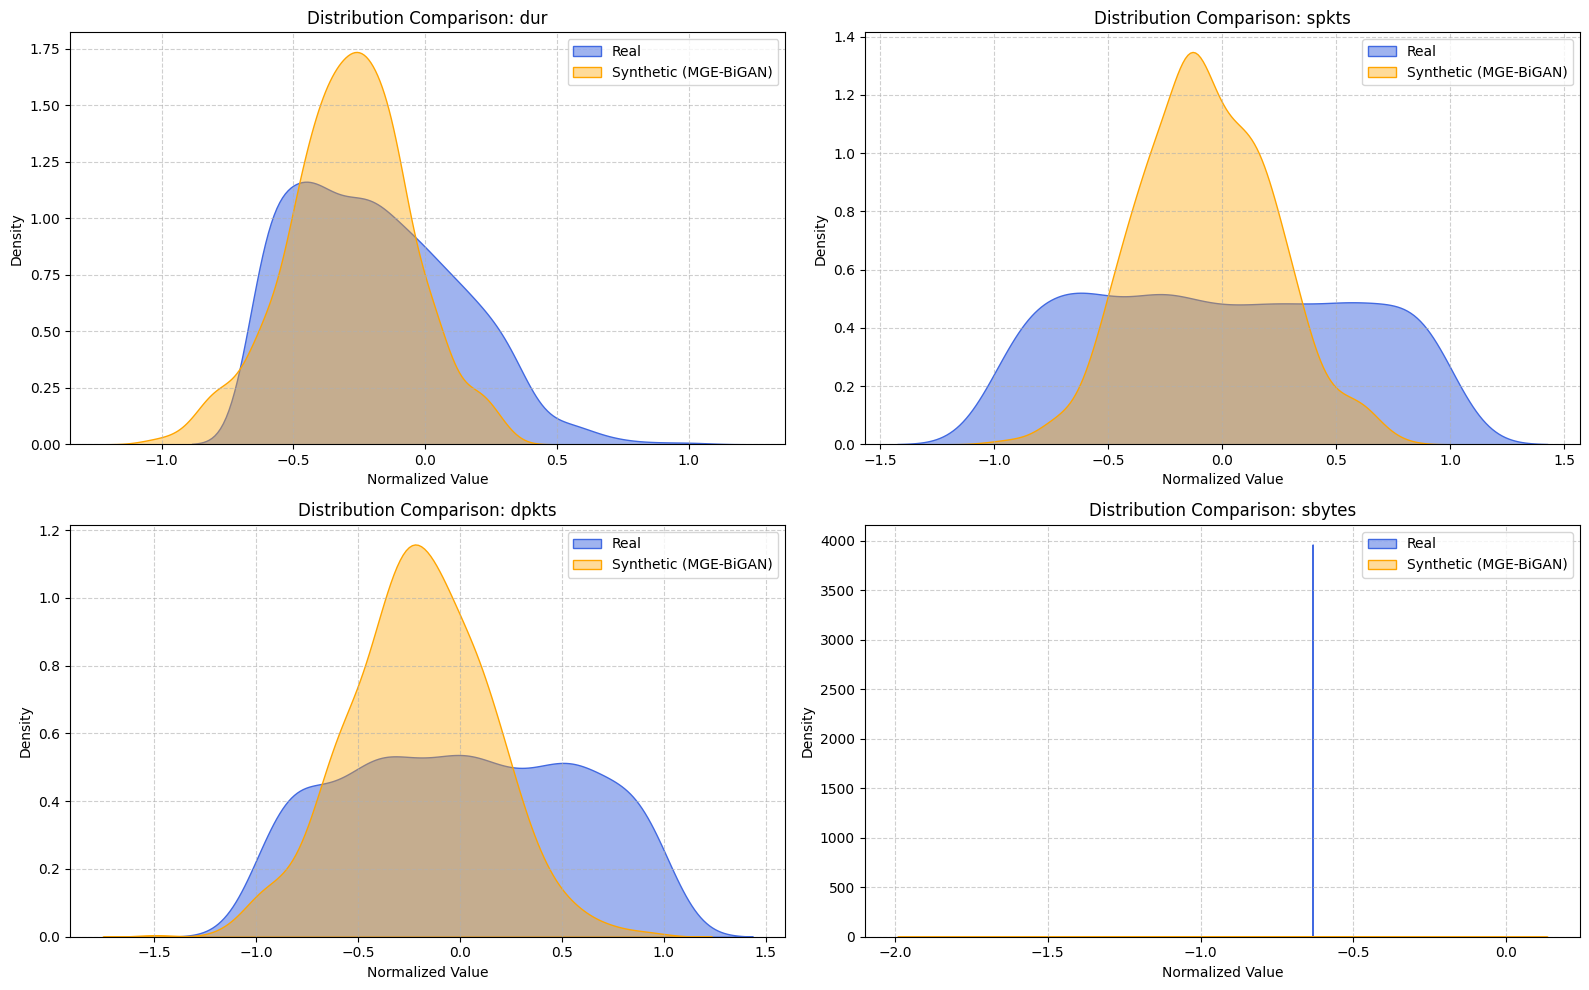

In [ ]:
# Cell 25: Visualize Real vs. Synthetic Feature Distributions
import matplotlib.pyplot as plt
import seaborn as sns

def plot_real_vs_synthetic_distributions(trainer, preprocessor, real_features, real_labels, num_samples=1000):
    trainer.generator.eval()
    trainer.embedding.eval()

    # 1. Gather a subset of real samples
    real_np = real_features[:num_samples].numpy()
    real_y_np = real_labels[:num_samples].numpy()

    # 2. Generate matching synthetic samples for the same target labels
    with torch.no_grad():
        z = torch.randn(num_samples, CONFIG.noise_dim, device=trainer.device)
        lbls = torch.tensor(real_y_np, dtype=torch.long, device=trainer.device)
        e_c = trainer.embedding(lbls)
        synthetic_np = trainer.generator(z, e_c, lbls).cpu().numpy()

    # Pick a few key numeric dimensions to plot
    num_plots = min(4, len(preprocessor.numeric_cols))
    plt.figure(figsize=(16, 10))

    for i in range(num_plots):
        plt.subplot(2, 2, i + 1)
        col_name = preprocessor.numeric_cols[i]

        # Plot KDE curves
        sns.kdeplot(real_np[:, i], label='Real', fill=True, alpha=0.5, color='royalblue', common_grid=True)
        sns.kdeplot(synthetic_np[:, i], label='Synthetic (MGE-BiGAN)', fill=True, alpha=0.4, color='orange', common_grid=True)

        plt.title(f"Distribution Comparison: {col_name}")
        plt.xlabel("Normalized Value")
        plt.ylabel("Density")
        plt.grid(True, linestyle='--', alpha=0.6)
        plt.legend()

    plt.tight_layout()
    plt.show()

# Run the visualization comparing real and synthetic distributions
plot_real_vs_synthetic_distributions(trainer, preprocessor, transform_features_tr, transform_labels_tr, num_samples=1000)

In [ ]:
# Generate the offline balanced synthetic dataset (Mode A) first
synthetic_balanced_df = generate_balanced_dataset(trainer, preprocessor, cap_per_class=500)

# Split features and labels
features_cols = [c for c in synthetic_balanced_df.columns if c.startswith("feat_")]
X_synth = synthetic_balanced_df[features_cols].values
y_synth = synthetic_balanced_df["class_idx"].values

# Retrieve actual classes mapped
target_names = [preprocessor.idx_to_class[i] for i in sorted(preprocessor.idx_to_class.keys())]

print(f"Synthetic balanced dataset size: {X_synth.shape}")
print(f"Unique classes in synthetic train set: {np.unique(y_synth)}")

# Train a Random Forest classifier strictly on synthetic balanced samples
synth_clf = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=CONFIG.seed, n_jobs=-1)
synth_clf.fit(X_synth, y_synth)

# Predict on actual, real held-out test telemetry data
y_real_pred = synth_clf.predict(X_te_np)

# Display classification report
print("==========================================================")
print("  TSTR REPORT (Train on Synthetic, Test on Real Telemetry) ")
print("==========================================================")
print(classification_report(
    y_te_np,
    y_real_pred,
    target_names=[t for i, t in enumerate(target_names) if i in np.unique(y_te_np)],
    labels=np.unique(y_te_np),
    zero_division=0
))
print("==========================================================")

Mode A: Balanced dataset saved successfully with 4000 synthetic records to artifacts/mge_bigan/synthetic_balanced_train.parquet
Synthetic balanced dataset size: (4000, 50)
Unique classes in synthetic train set: [1 2 3 4 5 6 7 8]
  TSTR REPORT (Train on Synthetic, Test on Real Telemetry) 
                precision    recall  f1-score   support

        normal       0.00      0.00      0.00      2541
      analysis       0.00      0.00      0.00        10
      backdoor       0.00      0.00      0.00         6
           dos       0.00      0.00      0.00        39
      exploits       0.03      0.30      0.06        97
       fuzzers       0.03      0.40      0.05        62
       generic       0.08      0.30      0.12       229
reconnaissance       0.00      0.00      0.00        16

     micro avg       0.04      0.04      0.04      3000
     macro avg       0.02      0.12      0.03      3000
  weighted avg       0.01      0.04      0.01      3000

